In [3]:
import os
import sys

if 'CONDA_PREFIX' in os.environ:
    # For Windows
    if sys.platform == 'win32':
        os.environ['GDAL_DATA'] = os.path.join(os.environ['CONDA_PREFIX'], 'Library', 'share', 'gdal')
        #os.environ['PROJ_LIB'] = os.path.join(os.environ['CONDA_PREFIX'], 'Library', 'share', 'proj')
    # For Linux / macOS
    else:
        os.environ['GDAL_DATA'] = os.path.join(os.environ['CONDA_PREFIX'], 'share', 'gdal')
        os.environ['PROJ_LIB'] = os.path.join(os.environ['CONDA_PREFIX'], 'share', 'proj')


In [4]:
import matplotlib.pyplot as plt

In [5]:
%load_ext autoreload
%autoreload 2

import fiona
import geopandas as gpd
import pandas as pd
import ultraplot as uplt

In [6]:
gdb_path = "../Data/CONUS_Region9_AllYears.gdb"
layers = fiona.listlayers(gdb_path)
print(layers)

['DAMAGE_AREAS_FLAT_AllYears_CONUS_Rgn9', 'DAMAGE_POINTS_FLAT_Allyears_CONUS_Rgn9', 'SURVEYED_AREAS_FLAT_AllYears_CONUS_Rgn9']


In [7]:
df = gpd.read_file(gdb_path, layer=layers[0])

c:\Users\camer\miniforge3\envs\defoliation\Lib\site-packages\pyogrio\raw.py:200: RuntimeWarning: organizePolygons() received a polygon with more than 100 parts. The processing may be really slow.  You can skip the processing by setting METHOD=SKIP, or only make it analyze counter-clock wise parts by setting METHOD=ONLY_CCW if you can assume that the outline of holes is counter-clock wise defined. Further messages of this type will be suppressed.
  return ogr_read(


In [11]:
df.columns

Index(['DAMAGE_AREA_ID', 'CREATED_DATE', 'MODIFIED_DATE', 'REGION_ID', 'LABEL',
       'HOST_CODE', 'HOST', 'HOST_GROUP_CODE', 'HOST_GROUP', 'DCA_CODE',
       'DCA_COMMON_NAME', 'DAMAGE_TYPE_CODE', 'DAMAGE_TYPE',
       'PERCENT_AFFECTED_CODE', 'PERCENT_AFFECTED', 'PERCENT_MIN',
       'PERCENT_MAX', 'PERCENT_MID', 'NOTES', 'OBSERVATION_COUNT',
       'COLLECTION_MODE', 'SNAPGRID_ROW', 'SNAPGRID_COLUMN', 'AREA_TYPE',
       'ACRES', 'STATUS', 'SURVEY_YEAR', 'LEGACY_SEVERITY_CODE',
       'LEGACY_SEVERITY', 'LEGACY_PATTERN_CODE', 'LEGACY_PATTERN',
       'LEGACY_TPA', 'LEGACY_NO_TREES', 'LEGACY_FOREST_TYPE_CODE',
       'LEGACY_FOREST_TYPE', 'GRP', 'OBSERVATION_ID', 'IDS_DATA_SOURCE',
       'DATA_SOURCE_NAME', 'US_AREA', 'Shape_Length', 'Shape_Area',
       'geometry'],
      dtype='object')

In [12]:
for i in df['DCA_COMMON_NAME'].unique():
    print(i)

spruce budworm
oak skeletonizer
hardwood anthracnose
spongy moth
birch leafminer
snow-ice
unknown
decline complex
flooding-high water
oak wilt
aspen defoliation
wind-tornado/hurricane
jack pine budworm
hemlock woolly adelgid
forest tent caterpillar
large aspen tortrix
maple leafcutter
satin moth
browntail moth
abiotic agents
introduced basswood thrips
human caused fire
early birch leaf edgeminer
drought
anthracnose
conifer seedling weevil
pear thrips
blight
cherry scallop shell moth
Bruce spanworm
maple decline
gall midge
larch sawfly
bark beetles
logging damage
oak leaftier
beech bark disease complex
spruce beetle
oak decline
leafhopper
larch casebearer
leaf spots
mortality
locust leafminer
western tent caterpillar
southern pine beetle
ash yellows disease
fire
leafroller/seed moth
larch decline
aspen blotchminer
spring cankerworm
winter injury
greenstriped mapleworm
wild fire
eastern tent caterpillar
Nantucket pine tip moth
eastern larch beetle
land clearing
frost
fall cankerworm
pine

In [8]:
sm = df[df['DCA_COMMON_NAME'] == 'spongy moth']

In [9]:
borders = gpd.read_file("../Data/US_State_Boundaries/US_State_Boundaries.shp")
borders = borders.to_crs(sm.crs)

## Full range

In [ ]:
sm_year = sm.dissolve(by='SURVEY_YEAR')
sm_year['yearly_area_m2'] = sm_year['geometry'].area

<a list of 1 Line2D objects>

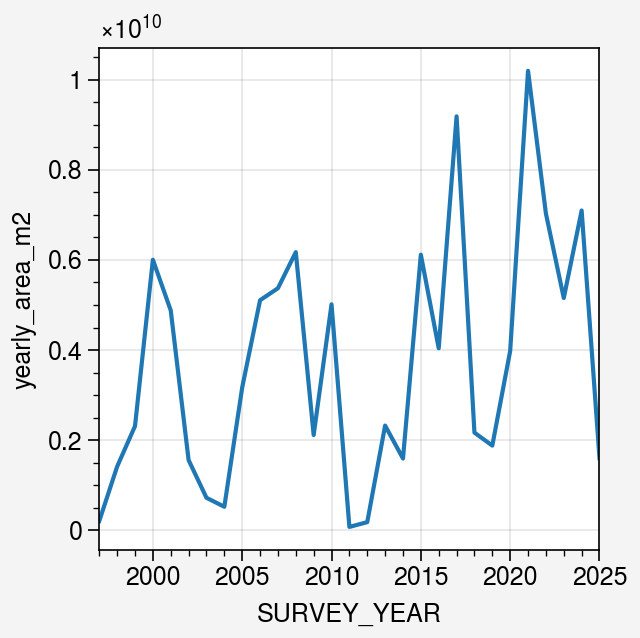

In [19]:
fig, ax = uplt.subplots()
ax.plot(sm_year.index, sm_year['yearly_area_m2'])

## New York

In [56]:
new_york = borders[borders['NAME'] == 'New York'].union_all()
sm_new_york = sm[sm.intersects(new_york)]
sm_new_york = sm_new_york.clip(new_york)

In [100]:
hist_ny = pd.read_csv('../Data/LD_digest/new_york.csv', thousands=',')
hist_ny['yearly_area_m2'] = hist_ny['Acres Defoliated'] * 4046.86
hist_ny.head()

,Year,Acres Defoliated,yearly_area_m2
0,1924,0,0.0
1,1925,0,0.0
2,1926,0,0.0
3,1927,0,0.0
4,1928,0,0.0


In [84]:
hist_ny = sm_hist[sm_hist.intersects(new_york)]
hist_ny = hist_ny.clip(new_york)

In [85]:
hist_ny_year = hist_ny.dissolve(by='RPT_YR')
hist_ny_year['yearly_area_m2'] = hist_ny_year['geometry'].area

In [86]:
sm_new_york_year = sm_new_york.dissolve(by='SURVEY_YEAR')
sm_new_york_year['yearly_area_m2'] = sm_new_york_year['geometry'].area

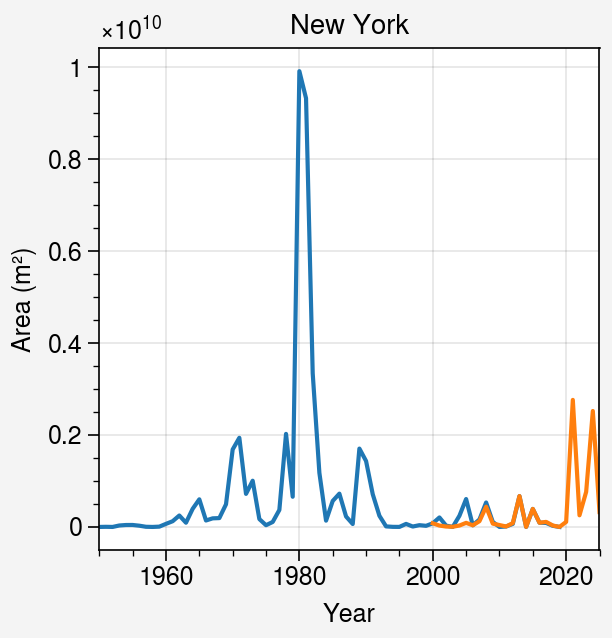

In [113]:
fig, ax = uplt.subplots()

ax.plot(hist_ny['Year'], hist_ny['yearly_area_m2'])
ax.plot(sm_new_york_year.index, sm_new_york_year['yearly_area_m2'])
ax.format(title='New York', xlabel='Year', ylabel='Area (m²)', xlim=(1950, 2025))

## Pennsylvania

In [49]:
penn = borders[borders['NAME'] == 'Pennsylvania'].union_all()
sm_penn = sm[sm.intersects(penn)]
sm_penn = sm_penn.clip(penn)

In [50]:
sm_penn_year = sm_penn.dissolve(by='SURVEY_YEAR')
sm_penn_year['yearly_area_m2'] = sm_penn_year['geometry'].area

In [107]:
hist_penn = pd.read_csv('../Data/LD_digest/pennsylvania.csv', thousands=',')
hist_penn['yearly_area_m2'] = hist_penn['Acres Defoliated'] * 4046.86
hist_penn.head()

,Year,Acres Defoliated,yearly_area_m2
0,2019,869,3.516721e+06
1,2018,5265,2.130672e+07
2,2017,54711,2.214078e+08
3,2016,76451,3.093865e+08
4,2015,694109,2.808962e+09


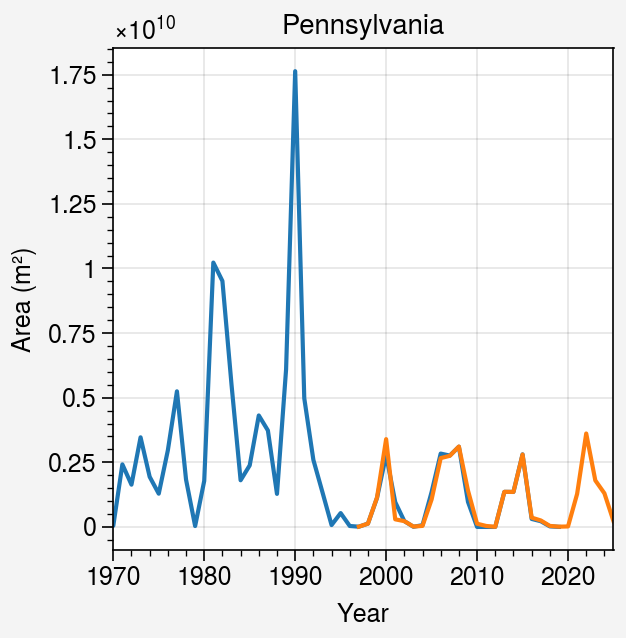

In [116]:
fig, ax = uplt.subplots()

ax.plot(hist_penn['Year'], hist_penn['yearly_area_m2'])
ax.plot(sm_penn_year.index, sm_penn_year['yearly_area_m2'])

ax.format(title='Pennsylvania', xlabel='Year', ylabel='Area (m²)', xlim=(1970, 2025))

## Massachussetts

In [60]:
mass = borders[borders['NAME'] == 'Massachusetts'].union_all()
sm_mass = sm[sm.intersects(mass)]
sm_mass = sm_mass.clip(mass)

In [97]:
hist_mass = pd.read_csv('../Data/LD_digest/massachussetts.csv', thousands=',')
hist_mass['yearly_area_m2'] = hist_mass['Acres Defoliated'] * 4046.86
hist_mass.head()

,Year,Acres Defoliated,yearly_area_m2
0,2019,10149,4.107158e+07
1,2018,173309,7.013573e+08
2,2017,1052436,4.259061e+09
3,2016,349806,1.415616e+09
4,2015,100078,4.050017e+08


In [78]:
sm_mass_year = sm_mass.dissolve(by='SURVEY_YEAR')
sm_mass_year['yearly_area_m2'] = sm_mass_year['geometry'].area

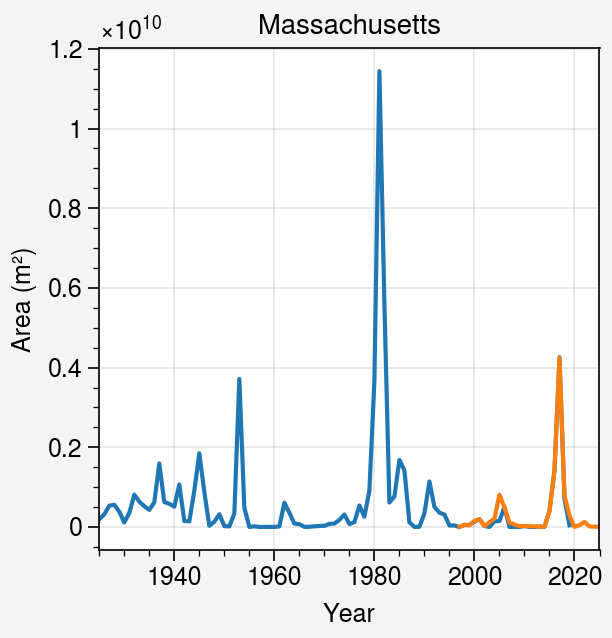

In [106]:
fig, ax = uplt.subplots()

ax.plot(hist_mass['Year'], hist_mass['yearly_area_m2'])
ax.plot(sm_mass_year.index, sm_mass_year['yearly_area_m2'])
ax.format(title='Massachusetts', xlabel='Year', ylabel='Area (m²)')
ax.format(xlim=(1925, 2025))

## Michigan

In [117]:
mich = borders[borders['NAME'] == 'Michigan'].union_all()
sm_mich = sm[sm.intersects(mich)]
sm_mich = sm_mich.clip(mich)

In [118]:
sm_mich_year = sm_mich.dissolve(by='SURVEY_YEAR')
sm_mich_year['yearly_area_m2'] = sm_mich_year['geometry'].area

In [119]:
hist_mich = pd.read_csv('../Data/LD_digest/michigan.csv', thousands=',')
hist_mich['yearly_area_m2'] = hist_mich['Acres Defoliated'] * 4046.86
hist_mich.head()

,Year,Acres Defoliated,yearly_area_m2
0,2019,195795,7.923550e+08
1,2018,6515,2.636529e+07
2,2017,74808,3.027375e+08
3,2016,699,2.828755e+06
4,2015,914,3.698830e+06


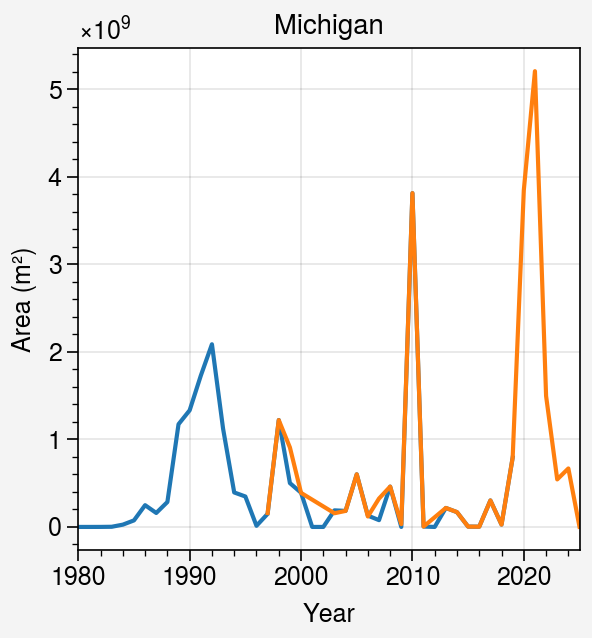

In [121]:
fig, ax = uplt.subplots()

ax.plot(hist_mich['Year'], hist_mich['yearly_area_m2'])
ax.plot(sm_mich_year.index, sm_mich_year['yearly_area_m2'])
ax.format(title='Michigan', xlabel='Year', ylabel='Area (m²)')
ax.format(xlim=(1980, 2025))

## Regional Diversity Showcase

In [ ]:
def gather_state_data(state_name, borders, sm):
    # Load modern survey data
    state_borders = borders[borders['NAME'] == state_name].union_all()
    sm_state = sm[sm.intersects(state_borders)]
    sm_state = sm_state.clip(state_borders)

    sm_state_year = sm_state.dissolve(by='SURVEY_YEAR')
    sm_state_year['yearly_area_km2'] = sm_state_year['geometry'].area/1_000_000

    # Load historical survey data
    hist_state = pd.read_csv(f'../Data/LD_digest/{state_name.lower().replace(" ", "_")}.csv', thousands=',')
    hist_state['yearly_area_km2'] = hist_state['Acres Defoliated'] * 4046.86 / 1_000_000

    return sm_state_year, hist_state

In [25]:
modern_mass, hist_mass = gather_state_data('Massachusetts', borders, sm)
modern_ny, hist_ny = gather_state_data('New York', borders, sm)
modern_penn, hist_penn = gather_state_data('Pennsylvania', borders, sm)

In [52]:
def plot_data(ax, sm_state, hist_state, state, start_year=1980, end_year=2025, **kwargs):
    modern_start_year = sm_state.index.min()
    hist_state = hist_state[hist_state['Year'] <= modern_start_year]

    ax.plot(hist_state['Year'], hist_state['yearly_area_km2']/1_000, label='', **kwargs)
    ax.plot(sm_state.index, sm_state['yearly_area_km2']/1_000, label='', **kwargs)
    ax.format(title=state, title_kw={'size':12}, xlabel='Year', ylabel='Area (x 1,000 km²)')
    ax.format(xlim=(start_year, end_year))

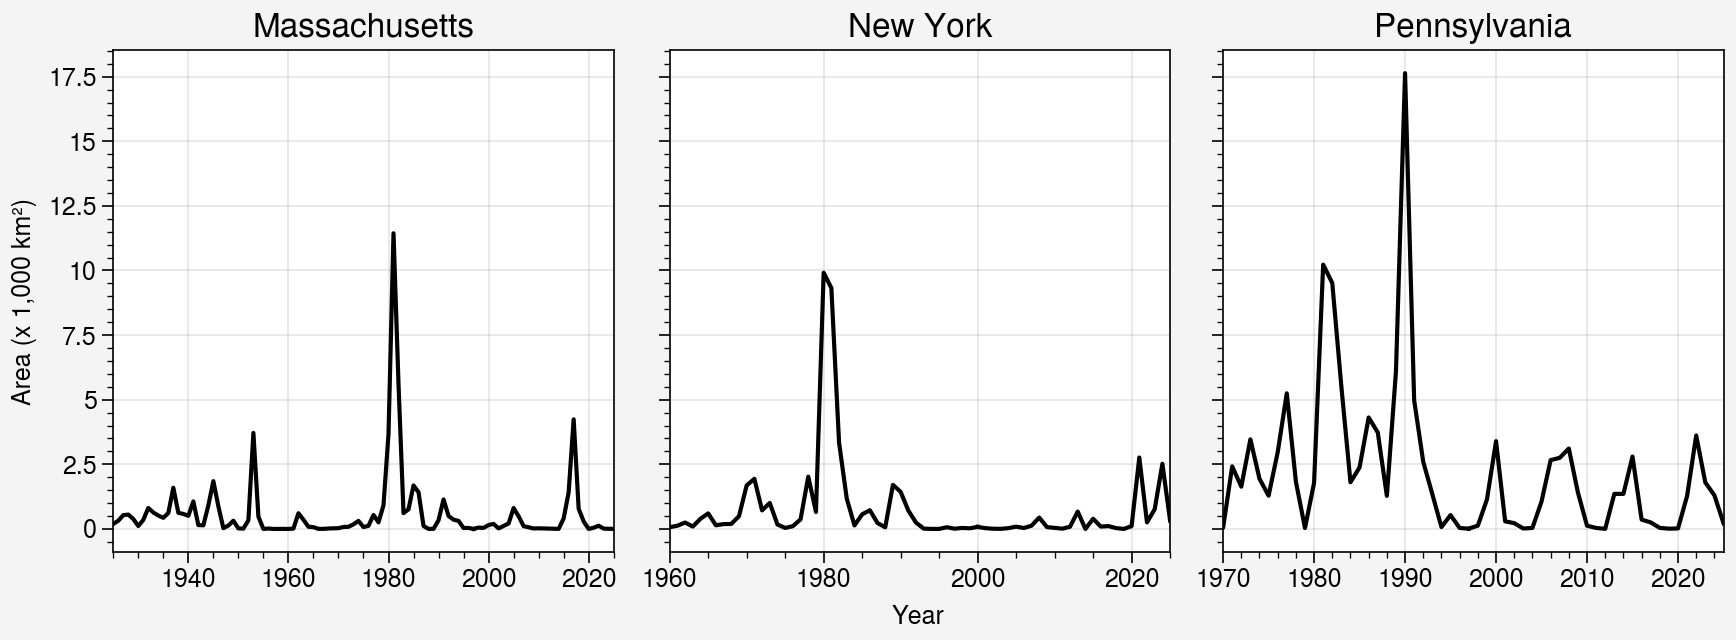

In [53]:
fig, axes = uplt.subplots(ncols=3)
plot_data(axes[0], modern_mass, hist_mass, 'Massachusetts', 1925, 2025, color='black')
plot_data(axes[1], modern_ny, hist_ny, 'New York', 1960, 2025, color='black')
plot_data(axes[2], modern_penn, hist_penn, 'Pennsylvania', 1970, 2025, color='black')

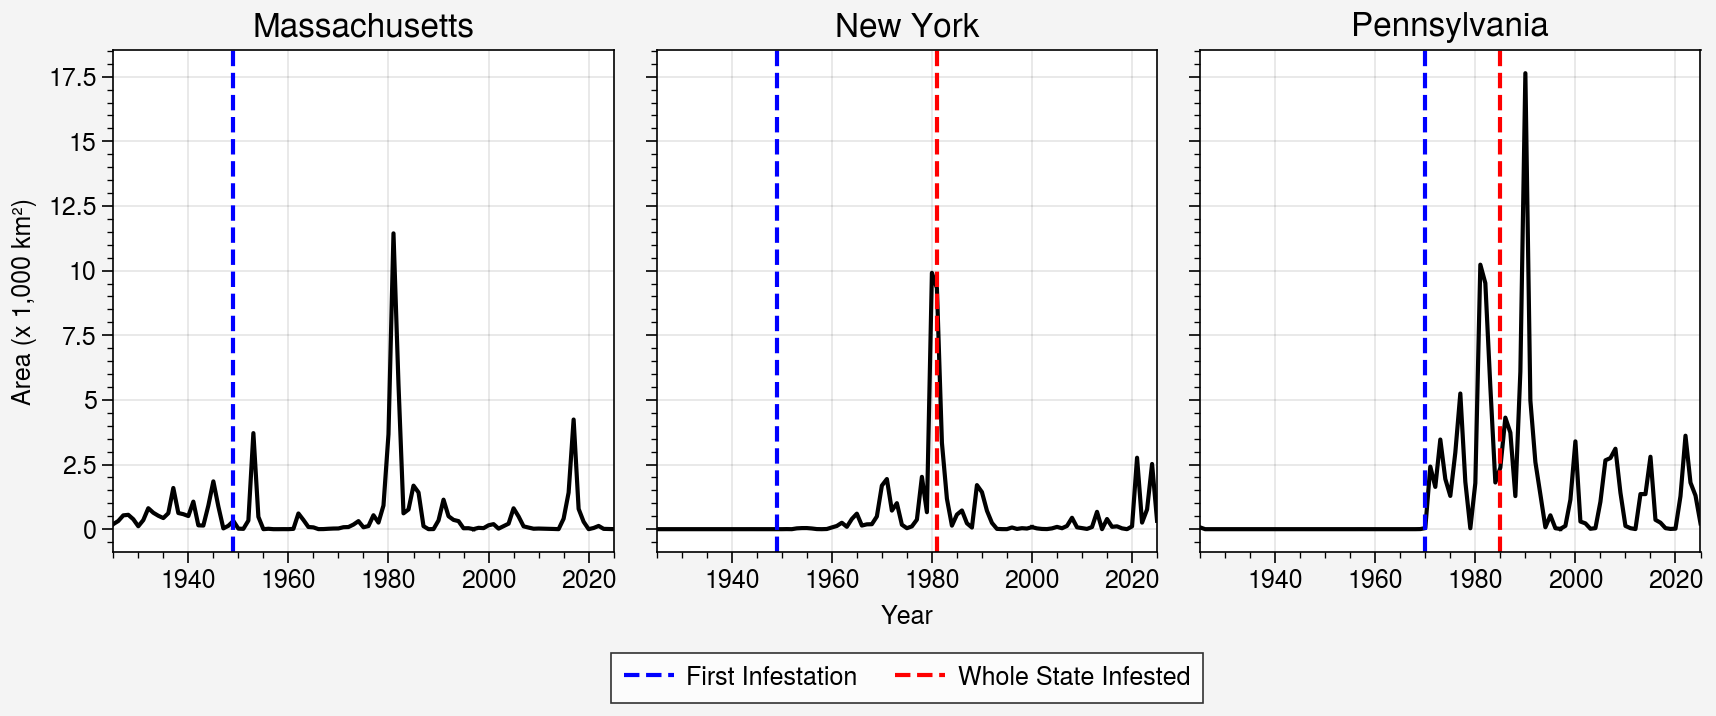

In [54]:
fig, axes = uplt.subplots(ncols=3)
plot_data(axes[0], modern_mass, hist_mass, 'Massachusetts', 1925, 2025, color='black')
axes[0].axvline(1949, color='blue', linestyle='--')
plot_data(axes[1], modern_ny, hist_ny, 'New York', 1925, 2025, color='black')
axes[1].axvline(1949, color='blue', linestyle='--', label='First Infestation')
axes[1].axvline(1981, color='red', linestyle='--', label='Whole State Infested')
plot_data(axes[2], modern_penn, hist_penn, 'Pennsylvania', 1925, 2025, color='black')
axes[2].axvline(1970, color='blue', linestyle='--')
axes[2].axvline(1985, color='red', linestyle='--')

fig.legend(loc='b')
fig.savefig('../Figures/Proposal/aerial_survey_trend_by_region.png', dpi=300, bbox_inches='tight')